In [17]:
###################################################################
# LAB – EDA BIVARIATE ANALYSIS: AMAZON UK PRODUCT INSIGHTS PART II
###################################################################
#
# In this lab we look at relationships between two variables at a time in the Amazon UK
# dataset: category vs best-seller status, category vs price and rating, and price vs rating.

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency
from scipy import stats

In [18]:
df = pd.read_csv("/Users/lena/Documents/IRONHACK DATA /Ironhack Data Analysis/WEEK 5/EDA Univariate Analysis Hands On/amz_uk_price_prediction_dataset.csv")
df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [19]:
df.shape

(2443651, 9)

In [20]:
# ===== PART 1 – BEST-SELLER TRENDS ACROSS CATEGORIES =====
#
# --- Crosstab ---

crosstab_result = pd.crosstab(df["category"], df["isBestSeller"])
crosstab_result

isBestSeller,False,True
category,,
3D Printers,247,1
3D Printing & Scanning,4065,2
Abrasive & Finishing Products,245,5
Action Cameras,1696,1
Adapters,251,3
...,...,...
Wind Instruments,243,7
Window Treatments,234,5
Women,17559,213


In [23]:
# proportion of best-sellers in each category, sorted from highest to lowest

bestseller_proportion = crosstab_result[True] / crosstab_result.sum(axis=1)
bestseller_proportion = bestseller_proportion.sort_values(ascending=False) 
bestseller_proportion.head(10) 

category
Grocery                           0.058135
Smart Home Security & Lighting    0.057692
Health & Personal Care            0.057686
Mobile Phone Accessories          0.042471
Power & Hand Tools                0.035339
Billiard, Snooker & Pool          0.032129
Pet Supplies                      0.030200
Home Brewing & Wine Making        0.028455
Wind Instruments                  0.028000
Mirrors                           0.028000
dtype: float64

In [28]:
print("Best-seller proportion in the whole dataset:", df["isBestSeller"].mean())
print("Categories with no best-seller at all:", (bestseller_proportion == 0).sum())
print("Best-seller % in the whole dataset:", df["isBestSeller"].mean() * 100)

# Yes, best-sellers are more common in some categories. Grocery (5.8%), Smart Home
# Security & Lighting (5.8%) and Health & Personal Care (5.8%) have the highest
# proportions, while in the whole dataset only 0.3% of products are best-sellers.
# 36 categories have no best-seller at all. But even in the best categories, more than 94%
# of products are not best-sellers.

Best-seller proportion in the whole dataset: 0.003265605440384081
Categories with no best-seller at all: 36
Best-seller % in the whole dataset: 0.3265605440384081


In [29]:
# --- Chi-square test ---

# H0: best-seller status is independent of the category
# H1: best-seller status depends on the category

chi2_statistic, chi2_p_value, dof, expected = chi2_contingency(crosstab_result)
print("Chi2:", chi2_statistic)
print("p-value:", chi2_p_value)

# The p-value is 0 (smaller than 0.05), so we reject H0: best-seller status is not
# independent of the category.

Chi2: 36540.20270061387
p-value: 0.0


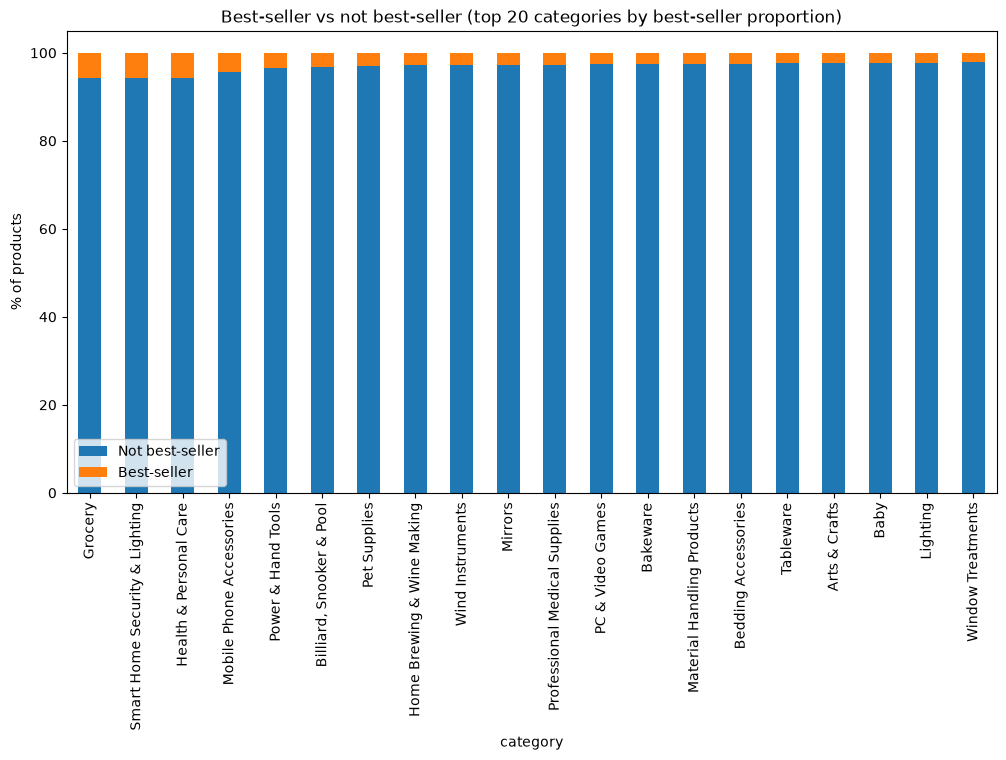

In [30]:
# --- Stacked bar chart ---
# With 296 categories the chart can't be read, so I only plot the 20 categories with the
# highest best-seller proportion, using percentages instead of counts.

crosstab_percent = pd.crosstab(df["category"], df["isBestSeller"], normalize="index") * 100
top20_percent = crosstab_percent.sort_values(True, ascending=False).head(20)

top20_percent.plot(kind="bar", stacked=True, figsize=(12, 6))
plt.title("Best-seller vs not best-seller (top 20 categories by best-seller proportion)")
plt.ylabel("% of products")
plt.legend(["Not best-seller", "Best-seller"])
plt.show()

# Even in these 20 categories, the best-sellers are only a small part at the top of each
# bar (less than 6%).

In [31]:
# ===== PART 2 – PRICES AND RATINGS ACROSS CATEGORIES =====
#
# --- Step 0: remove price outliers with the IQR method ---

def tukeys_test_outliers(data):
    Q1 = data.quantile(0.25)
    Q3 = data.quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers = data[(data < lower_bound) | (data > upper_bound)]
    return outliers

outliers = tukeys_test_outliers(df["price"])
print("Number of outliers:", len(outliers))

df_no_outliers = df.drop(outliers.index)
print("Rows before:", len(df), "Rows after:", len(df_no_outliers))
print("Max price now:", df_no_outliers["price"].max())

# 327,688 products above £99.99 are removed. The lower limit is negative, so no cheap
# products are removed.

Number of outliers: 327688
Rows before: 2443651 Rows after: 2115963
Max price now: 99.99


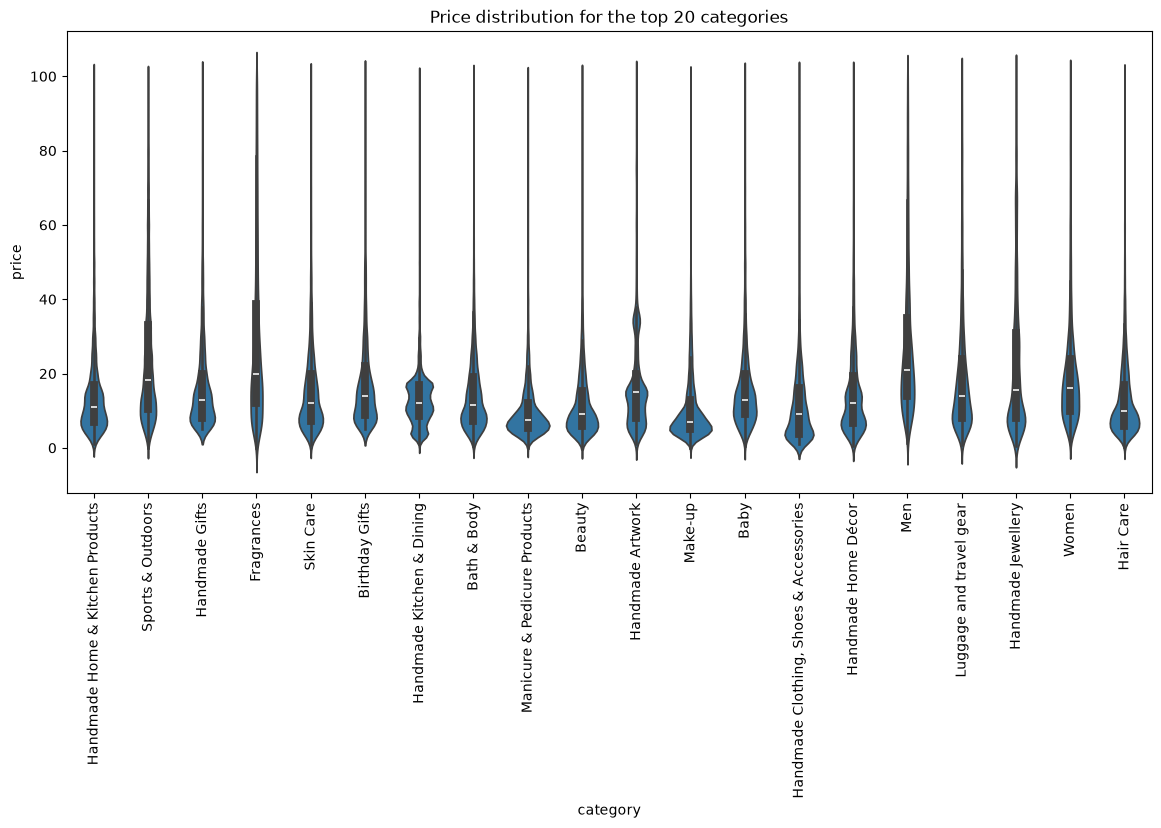

In [32]:
# --- Violin plot (top 20 categories by count) ---

top20_categories = df_no_outliers["category"].value_counts().head(20).index
df_top20 = df_no_outliers[df_no_outliers["category"].isin(top20_categories)]

plt.figure(figsize=(14, 6))
sns.violinplot(data=df_top20, x="category", y="price")
plt.xticks(rotation=90)
plt.title("Price distribution for the top 20 categories")
plt.show()

# Most categories have their prices concentrated under £20, with a long tail up to £100.
# Fragrances, Men and Sports & Outdoors have higher and more spread out prices, while
# Make-up and Manicure & Pedicure products are the cheapest.

In [33]:
# category with the highest median price (all categories)
df_no_outliers.groupby("category")["price"].median().sort_values(ascending=False).head(10)

# Desktop PCs has the highest median price (£74), followed by Boxing Shoes, Tablets,
# Graphics Cards and Motherboards. Note: this is after removing everything above £99.99,
# so these are only the cheaper products of these categories.

category
Desktop PCs               74.00
Boxing Shoes              69.79
Tablets                   69.00
Graphics Cards            68.54
Motherboards              67.92
Made in Italy Handmade    64.00
Digital Frames            63.90
Streaming Clients         62.68
Golf Shoes                62.39
Ski Helmets               61.33
Name: price, dtype: float64

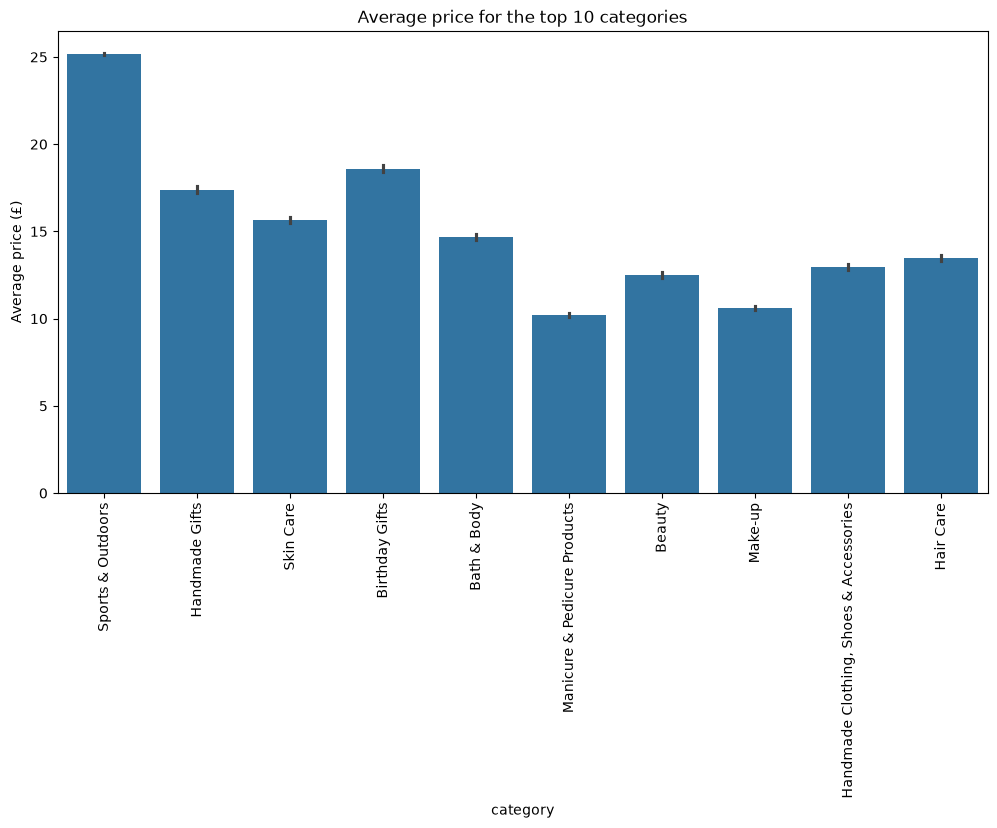

In [34]:
# --- Bar chart: average price for the top 10 categories by count ---

top10_categories = df_no_outliers["category"].value_counts().head(10).index
df_top10 = df_no_outliers[df_no_outliers["category"].isin(top10_categories)]

plt.figure(figsize=(12, 6))
sns.barplot(data=df_top10, x="category", y="price")
plt.xticks(rotation=90)
plt.title("Average price for the top 10 categories")
plt.ylabel("Average price (£)")
plt.show()

# Sports & Outdoors has the highest average price of the top 10 (about £25). The beauty
# categories like Make-up and Manicure & Pedicure are the cheapest (about £10).

In [35]:
# category with the highest average price (all categories)
df_no_outliers.groupby("category")["price"].mean().sort_values(ascending=False).head(10)

# Motherboards has the highest average price (about £69), then Boxing Shoes and Desktop
# PCs. Mostly electronics / computer parts.

category
Motherboards         68.772432
Boxing Shoes         67.417803
Desktop PCs          66.915562
Tablets              66.552971
Graphics Cards       65.103509
Digital Frames       60.745129
Streaming Clients    60.241803
Hockey Shoes         60.094796
Computer Cases       58.339884
Skiing Poles         57.867770
Name: price, dtype: float64

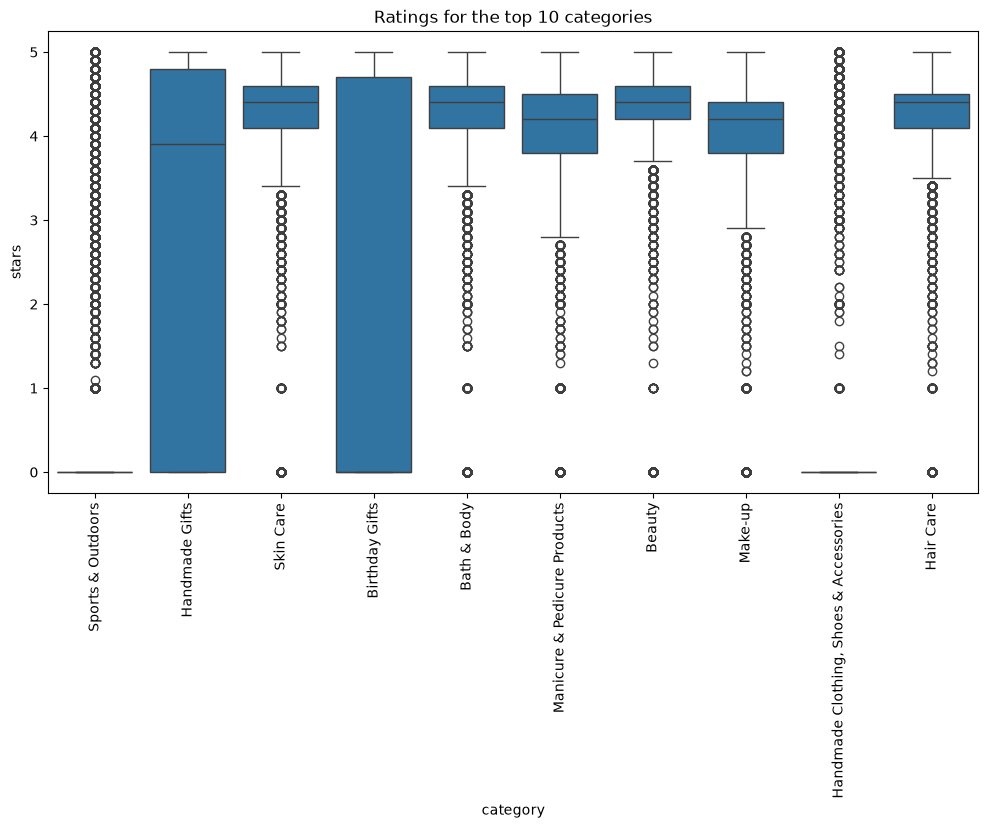

In [36]:
# --- Box plot: ratings for the top 10 categories ---

plt.figure(figsize=(12, 6))
sns.boxplot(data=df_top10, x="category", y="stars")
plt.xticks(rotation=90)
plt.title("Ratings for the top 10 categories")
plt.show()

# For Sports & Outdoors and Handmade Clothing the whole box is at 0, and for Birthday
# Gifts and Handmade Gifts the box goes down to 0. This is because many of their products
# have no rating yet (0 stars = no reviews, like we found in the univariate lab). The
# beauty categories have a median around 4.2-4.4.

In [37]:
# category with the highest median rating (all categories)
df_no_outliers.groupby("category")["stars"].median().sort_values(ascending=False).head(10)

# Computer Memory has the highest median rating (4.7). Several categories have 4.6, for
# example Kids' Play Figures, Beer Wine & Spirits and Office Paper Products.

category
Computer Memory                 4.7
Building & Construction Toys    4.6
Office Paper Products           4.6
Luxury Food & Drink             4.6
Kids' Play Figures              4.6
Hobbies                         4.6
Beer, Wine & Spirits            4.6
Laptop Accessories              4.6
Cables & Accessories            4.5
CPUs                            4.5
Name: stars, dtype: float64

In [16]:
# ===== PART 3 – PRICE VS RATING =====
#
# --- Correlation coefficients ---

pearson = df_no_outliers["price"].corr(df_no_outliers["stars"])
spearman = df_no_outliers["price"].corr(df_no_outliers["stars"], method="spearman")
print("Pearson:", pearson)
print("Spearman:", spearman)

Pearson: -0.07767299878181323
Spearman: -0.06679697280768307


In [38]:
# is the correlation significant? (p-value)
result = stats.pearsonr(df_no_outliers["price"], df_no_outliers["stars"])
print(result)

# The correlation is about -0.08 (Pearson) and -0.07 (Spearman). The p-value is 0 so it is
# "statistically significant", but only because we have 2 million rows. The correlation is
# so close to 0 that maybe there is no real relationship between price and rating?

PearsonRResult(statistic=np.float64(-0.07767299878181345), pvalue=np.float64(0.0))


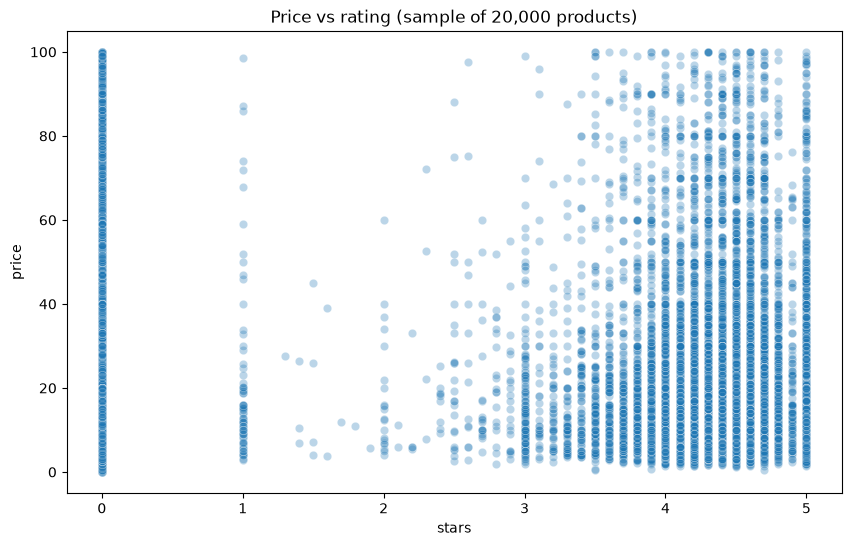

In [39]:
# --- Scatter plot ---
# With 2 million points the plot is very slow, so I use a random sample of 20,000 products.

sample = df_no_outliers.sample(20000, random_state=42)

plt.figure(figsize=(10, 6))
sns.scatterplot(data=sample, x="stars", y="price", alpha=0.3)
plt.title("Price vs rating (sample of 20,000 products)")
plt.show()

# There is no clear pattern. There is a vertical line of points at 0 stars (products
# without a rating), and the other points are mostly between 3.5 and 5 stars at all
# prices. Expensive and cheap products get similar ratings.

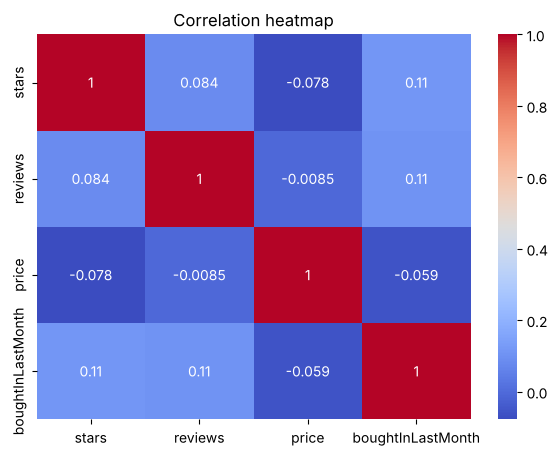

In [19]:
# --- Correlation heatmap of the numerical variables ---

numerical = df_no_outliers[["stars", "reviews", "price", "boughtInLastMonth"]]
correlation_matrix = numerical.corr()

plt.figure(figsize=(7, 5))
sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm")
plt.title("Correlation heatmap")
plt.show()

# All the correlations are weak (between -0.08 and 0.11). The strongest are stars vs
# boughtInLastMonth (0.11) and reviews vs boughtInLastMonth (0.11). I did not include uid
# because it is just an ID number.

In [20]:
# ===== REPORT =====
#
# Best-sellers and categories. Only 0.3% of all products are best-sellers. Some categories
# have more best-sellers than others (Grocery, Smart Home Security & Lighting and Health &
# Personal Care are close to 6%), and 36 categories have none. The Chi-square test shows
# that best-seller status depends on the category (p-value = 0). But even in the best
# categories, less than 6% of products are best-sellers, so for a seller the category
# matters a bit, but other things (price, reviews, marketing) probably matter more.
#
# Prices across categories. After removing the outliers (products above £99.99),
# electronics and computer categories like Desktop PCs, Tablets, Graphics Cards and
# Motherboards have the highest median and average prices. Among the 10 biggest
# categories, Sports & Outdoors is the most expensive on average (about £25) and the
# beauty categories are the cheapest (about £10). Pricing should be compared inside the
# same category, because typical prices are very different between categories.
#
# Ratings across categories. Computer Memory has the highest median rating (4.7), and many
# categories are around 4.4-4.6. In some big categories (Sports & Outdoors, Birthday
# Gifts, Handmade Clothing) most products have no rating yet, so their median is 0. Getting
# the first reviews is important to stand out in these categories.
#
# Price vs rating. There is almost no correlation between price and rating (about -0.08).
# Cheaper products are not rated worse and expensive products are not rated better, so a
# seller does not need a high price to get good ratings. All numerical variables have weak
# correlations with each other.